# cfDNA ctDNA-Stratified Cancer Detection (Figure 5f-g)

Reads tables from `../data/` and writes figures to `../output/`.
Source notebook: `../../NOTEBOOK_PROVENANCE.tsv`.

Panels:
-  `cfdna_ctdna_bin_auc`: LEAF-1 vs DELFI (100k features) AUC by ctDNA tertile bin.
-  `cfdna_ctdna_logit_forest`: Median logit predicted probability by cancer type and ctDNA group.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)

DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output


In [2]:
# ── Shared constants and helper functions ─────────────────────────────────────
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.metrics import roc_auc_score

CANCERS = ["Bile_duct", "Breast", "Colorectal", "Gastric", "Lung", "Ovarian", "Pancreatic"]
COMPARISONS = ["vs_healthy", "vs_other_cancers"]
CTDNA_BIN_ORDER = ["low_ctDNA", "medium_ctDNA", "high_ctDNA"]
CTDNA_BIN_LABELS = {"low_ctDNA": "Low ctDNA", "medium_ctDNA": "Medium ctDNA", "high_ctDNA": "High ctDNA"}
LEAF1_COL = "prob_ensemble"
DELFI_OOF_COL = "delfi_oof_score"
META_DELFI_COL = "meta_delfi_score"

def _add_task_parts(frame):
    out = frame.copy(); out["cancer"] = pd.NA; out["comparison"] = pd.NA
    for c in CANCERS:
        for cmp in COMPARISONS:
            mask = out["task"] == f"{c}_cancer_{cmp}"
            out.loc[mask, "cancer"] = c; out.loc[mask, "comparison"] = cmp
    return out

def _sem(v):
    s = pd.Series(v, dtype="float64").dropna()
    return np.nan if len(s) < 2 else float(s.std(ddof=1) / np.sqrt(len(s)))

def _paired_pvalue(frame):
    p = frame[["leaf1_auc", "delfi_auc"]].dropna()
    if len(p) < 2: return np.nan
    d = (p["leaf1_auc"] - p["delfi_auc"]).to_numpy(dtype=float)
    if np.allclose(d, 0): return 1.0
    try: return float(wilcoxon(p["leaf1_auc"], p["delfi_auc"]).pvalue)
    except ValueError: return np.nan

def _fmt_p(pv):
    if pd.isna(pv): return "p=NA"
    return "p<0.001" if pv < 0.001 else f"p={pv:.3f}"

def _logit(prob, eps=1e-6):
    c = np.clip(np.asarray(prob, dtype=float), eps, 1 - eps)
    return np.log(c / (1 - c))

def _bsci(vals, n=10000, seed=42):
    a = pd.Series(vals, dtype="float64").dropna().to_numpy()
    if len(a) == 0: return np.nan, np.nan
    if len(a) == 1: return float(a[0]), float(a[0])
    rng = np.random.default_rng(seed)
    meds = np.median(rng.choice(a, size=(n, len(a)), replace=True), axis=1)
    return float(np.quantile(meds, 0.025)), float(np.quantile(meds, 0.975))

def _wilcoxon1(vals, null=0.0):
    a = pd.Series(vals, dtype="float64").dropna().to_numpy() - null
    if len(a) < 2: return np.nan
    if np.allclose(a, 0): return 1.0
    try: return float(wilcoxon(a).pvalue)
    except ValueError: return np.nan

def load_and_merge(with_delfi_oof=True):
    """Load leaf1 predictions, metadata, optionally DELFI OOF, and merge."""
    raw = pd.read_csv(DATA / "leaf1_oof_predictions.csv")
    preds = raw.drop_duplicates(subset=["sample_id", "task"], keep="first")
    preds = preds[~preds["true_group"].isin(["Duodenal_cancer", "Unknown"])].copy()
    preds = _add_task_parts(preds)
    preds = preds[preds["cancer"].notna()].copy()

    meta = pd.read_csv(DATA / "cfdna_metadata.csv")
    meta["ichorcna_tumor_fraction"] = pd.to_numeric(meta["ichorcna_tumor_fraction"], errors="coerce")
    if META_DELFI_COL in meta.columns:
        meta[META_DELFI_COL] = pd.to_numeric(meta[META_DELFI_COL], errors="coerce")

    keep = ["sample_id", "ichorcna_tumor_fraction", "meta_tumor_site", "group"]
    if META_DELFI_COL in meta.columns: keep.append(META_DELFI_COL)
    merged = preds.merge(meta[keep], on="sample_id", how="left", suffixes=("", "_meta"))
    if META_DELFI_COL not in merged.columns: merged[META_DELFI_COL] = np.nan

    if with_delfi_oof:
        doof = pd.read_csv(DATA / "delfi_oof_predictions.csv")
        if "feature_set" in doof.columns: doof = doof[doof["feature_set"] == "delfi"]
        if "model_kind" in doof.columns: doof = doof[doof["model_kind"] == "binning"]
        doof[DELFI_OOF_COL] = pd.to_numeric(doof["y_prob"], errors="coerce")
        doof = doof.dropna(subset=[DELFI_OOF_COL])
        doof_agg = doof.groupby(["sample_id", "task"], as_index=False).agg(
            delfi_oof_score=(DELFI_OOF_COL, "mean")
        )
        merged = merged.merge(doof_agg, on=["sample_id", "task"], how="left")
        if DELFI_OOF_COL not in merged.columns: merged[DELFI_OOF_COL] = np.nan
    return merged

def assign_bins(merged, method="tertile", cutoffs=(0.01, 0.03)):
    pos = (
        merged[(merged["label"] == 1) & merged["ichorcna_tumor_fraction"].notna()]
        [["sample_id", "ichorcna_tumor_fraction"]].drop_duplicates("sample_id").copy()
    )
    if method == "fixed":
        lo, hi = sorted(cutoffs)
        pos["ctdna_bin"] = pd.cut(
            pos["ichorcna_tumor_fraction"], bins=[-np.inf, lo, hi, np.inf],
            labels=CTDNA_BIN_ORDER, include_lowest=True,
        ).astype("object")
        return pos
    try:
        pos["ctdna_bin"] = pd.qcut(pos["ichorcna_tumor_fraction"], q=3, labels=CTDNA_BIN_ORDER).astype("object")
    except ValueError:
        bins = pd.qcut(pos["ichorcna_tumor_fraction"], q=3, duplicates="drop")
        lmap = dict(zip(list(bins.cat.categories), CTDNA_BIN_ORDER[:len(bins.cat.categories)]))
        pos["ctdna_bin"] = bins.map(lmap).astype("object")
    return pos

def compute_bin_auc_summary(merged, delfi_col):
    assignments = assign_bins(merged)
    vsh = merged[merged["comparison"] == "vs_healthy"].merge(
        assignments[["sample_id", "ctdna_bin"]], on="sample_id", how="left"
    )
    rows = []
    for cancer in CANCERS:
        task_df = vsh[vsh["task"] == f"{cancer}_cancer_vs_healthy"]
        healthy = task_df[task_df["label"] == 0]
        for b in CTDNA_BIN_ORDER:
            pos = task_df[(task_df["label"] == 1) & (task_df["ctdna_bin"] == b)]
            m = pd.concat([pos, healthy], ignore_index=True).dropna(subset=[LEAF1_COL, delfi_col, "label"])
            row = {"cancer": cancer, "ctdna_bin": b, "leaf1_auc": np.nan, "delfi_auc": np.nan, "leaf1_minus_delfi": np.nan}
            if m["label"].nunique() == 2:
                row["leaf1_auc"] = float(roc_auc_score(m["label"], m[LEAF1_COL]))
                row["delfi_auc"] = float(roc_auc_score(m["label"], m[delfi_col]))
                row["leaf1_minus_delfi"] = row["leaf1_auc"] - row["delfi_auc"]
            rows.append(row)
    by_cancer = pd.DataFrame(rows)
    summ = []
    for b in CTDNA_BIN_ORDER:
        sub = by_cancer[(by_cancer["ctdna_bin"] == b) & by_cancer["leaf1_auc"].notna() & by_cancer["delfi_auc"].notna()]
        summ.append({
            "ctdna_bin": b, "ctdna_bin_label": CTDNA_BIN_LABELS[b],
            "leaf1_auc_mean": float(sub["leaf1_auc"].mean()) if len(sub) else np.nan,
            "leaf1_auc_sem": _sem(sub["leaf1_auc"]),
            "delfi_auc_mean": float(sub["delfi_auc"].mean()) if len(sub) else np.nan,
            "delfi_auc_sem": _sem(sub["delfi_auc"]),
            "pvalue": _paired_pvalue(sub),
        })
    return pd.DataFrame(summ), assignments

print("helpers loaded")

helpers loaded


saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_ctdna_bin_auc.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_ctdna_bin_auc.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_ctdna_bin_auc.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_ctdna_bin_auc.tsv


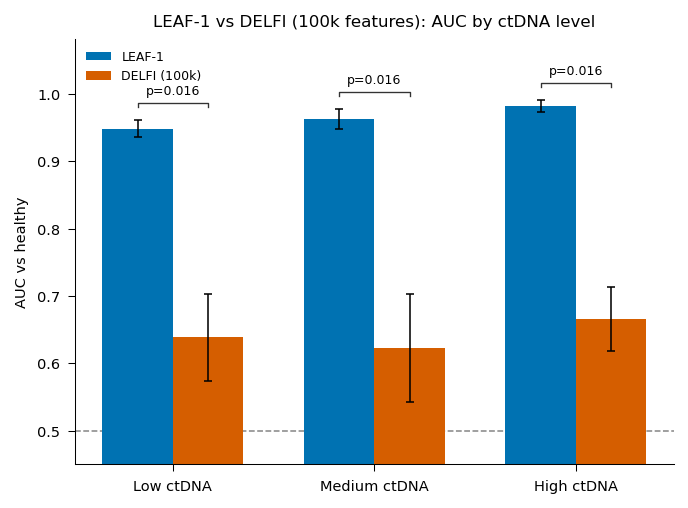

In [ ]:
# ── Figure 5f: LEAF-1 vs DELFI (100k features) AUC by ctDNA bin ──────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

merged = load_and_merge(with_delfi_oof=True)
summary, _ = compute_bin_auc_summary(merged, delfi_col=DELFI_OOF_COL)

plot_df = summary.set_index("ctdna_bin").reindex(CTDNA_BIN_ORDER).reset_index()
x = np.arange(len(plot_df)); w = 0.35
fig, ax = plt.subplots(figsize=(4.6, 3.4))
ax.axhline(0.5, color='#888888', linestyle='--', linewidth=0.75, zorder=1)
ax.bar(x - w/2, plot_df['leaf1_auc_mean'], w, yerr=plot_df['leaf1_auc_sem'], capsize=2,
       label='LEAF-1', color='#0072B2', edgecolor='none',
       error_kw={'linewidth': 0.75, 'capthick': 0.75}, zorder=2)
ax.bar(x + w/2, plot_df['delfi_auc_mean'], w, yerr=plot_df['delfi_auc_sem'], capsize=2,
       label='DELFI (100k)', color='#D55E00', edgecolor='none',
       error_kw={'linewidth': 0.75, 'capthick': 0.75}, zorder=2)
y_tops = np.nanmax(np.vstack([
    plot_df['leaf1_auc_mean'] + plot_df['leaf1_auc_sem'].fillna(0),
    plot_df['delfi_auc_mean'] + plot_df['delfi_auc_sem'].fillna(0),
]), axis=0)
for xi, yt, pv in zip(x, y_tops, plot_df['pvalue']):
    if pd.isna(yt): continue
    y = yt + 0.025
    ax.plot([xi-w/2, xi-w/2, xi+w/2, xi+w/2], [y-0.006, y, y, y-0.006], color='#333333', linewidth=0.65)
    ax.text(xi, y + 0.008, _fmt_p(pv), ha='center', va='bottom', fontsize=6)
ax.set_xticks(x)
ax.set_xticklabels([CTDNA_BIN_LABELS.get(v, v) for v in plot_df['ctdna_bin']])
ax.set_ylabel('AUC vs healthy')
ax.set_title('LEAF-1 vs DELFI (100k features): AUC by ctDNA level', fontsize=8)
ymax = float(np.nanmax(y_tops)) if len(y_tops) else 1.0
ax.set_ylim(0.45, max(1.04, ymax + 0.09))
ax.legend(frameon=False, fontsize=6)
fig.tight_layout()
savefig(fig, OUT, 'cfdna_ctdna_bin_auc', data=(plot_df))
plt.show()

/home/hamedh/bin/miniforge3/envs/bch/lib/python3.10/site-packages/scipy/stats/_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
/home/hamedh/bin/miniforge3/envs/bch/lib/python3.10/site-packages/scipy/stats/_morestats.py:4102: UserWarning: Sample size too small for normal approximation.
  warnings.warn("Sample size too small for normal approximation.")
/home/hamedh/bin/miniforge3/envs/bch/lib/python3.10/site-packages/scipy/stats/_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
/home/hamedh/bin/miniforge3/envs/bch/lib/python3.10/site-packages/scipy/stats/_morestats.py:4102: UserWarning: Sample size too small for normal approximation.
  warnings.warn("Sample size too small for normal approxima

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_ctdna_logit_forest.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_ctdna_logit_forest.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_ctdna_logit_forest.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/cfdna/output/cfdna_ctdna_logit_forest.tsv


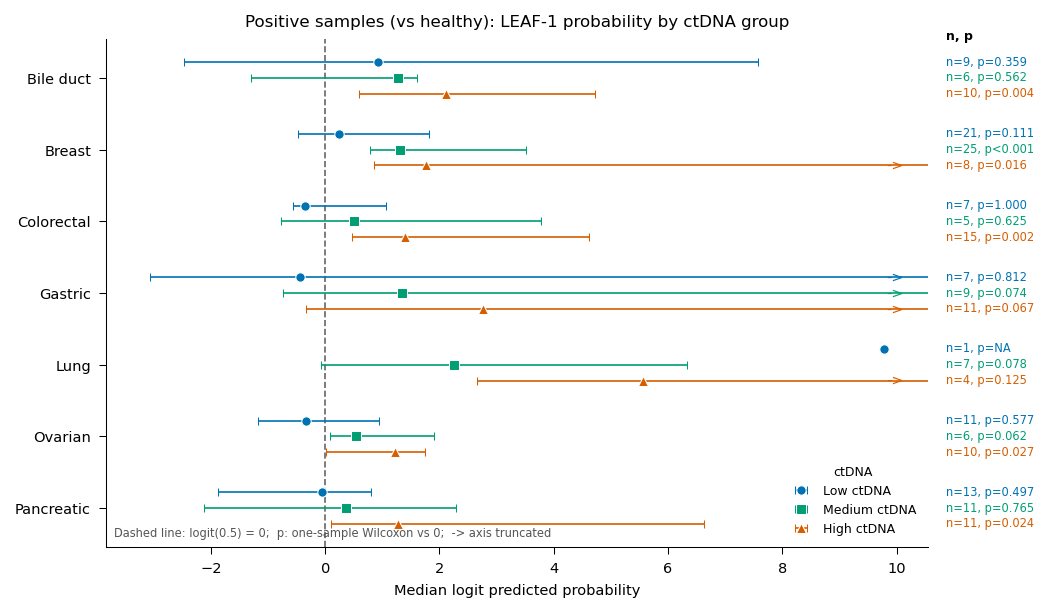

In [ ]:
# ── Figure 5g: Logit predicted probability forest by ctDNA group ──────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

merged = load_and_merge(with_delfi_oof=False)
_, assignments = compute_bin_auc_summary(merged, delfi_col=META_DELFI_COL)
pos_preds = (
    merged[(merged["label"] == 1) & merged["ichorcna_tumor_fraction"].notna()].copy()
    .merge(assignments[["sample_id", "ctdna_bin"]], on="sample_id", how="left")
)

# Compute forest summary
sub = pos_preds[pos_preds["comparison"] == "vs_healthy"].copy()
rows = []
for ci, cancer in enumerate(CANCERS):
    for bi, b in enumerate(CTDNA_BIN_ORDER):
        one = sub[(sub["cancer"] == cancer) & (sub["ctdna_bin"] == b)]
        lp = pd.Series(_logit(one[LEAF1_COL]), index=one.index, dtype="float64")
        ci_lo, ci_hi = _bsci(lp, seed=42 + ci * 10 + bi)
        pv = _wilcoxon1(lp, null=0.0)
        rows.append({
            "cancer": cancer, "ctdna_bin": b, "n": len(one),
            "median_logit": float(lp.median()) if len(lp) > 0 else np.nan,
            "ci_low": ci_lo, "ci_high": ci_hi,
            "p_label": _fmt_p(pv),
        })
forest = pd.DataFrame(rows)

# Plot
offsets = {"low_ctDNA": -0.22, "medium_ctDNA": 0.0, "high_ctDNA": 0.22}
colors  = {"low_ctDNA": "#0072B2", "medium_ctDNA": "#009E73", "high_ctDNA": "#D55E00"}
markers = {"low_ctDNA": "o", "medium_ctDNA": "s", "high_ctDNA": "^"}
y_base  = np.arange(len(CANCERS))

all_fin = forest[["median_logit", "ci_low", "ci_high"]].to_numpy(dtype=float).ravel()
all_fin = all_fin[np.isfinite(all_fin)]
if len(all_fin) == 0: x_min, x_hi = -1.0, 1.0
else:
    x_min = float(np.min(all_fin))
    x_hi  = float(np.percentile(all_fin, 90))
    if np.isclose(x_min, x_hi): x_min -= 0.5; x_hi += 0.5
x_pad = max(0.3, (x_hi - x_min) * 0.06)
label_x = x_hi + x_pad * 1.4

fig, ax = plt.subplots(figsize=(7.0, 4.1))
ax.axvline(0, color='#666666', linestyle='--', linewidth=0.8, zorder=1)
ax.text(label_x, -0.58, 'n, p', ha='left', va='center', fontsize=6, fontweight='bold', clip_on=False)

for b in CTDNA_BIN_ORDER:
    one = forest[forest["ctdna_bin"] == b].set_index("cancer").reindex(CANCERS)
    y  = y_base + offsets[b]
    xv = one["median_logit"].to_numpy(dtype=float)
    xerr = np.vstack([xv - one["ci_low"].to_numpy(dtype=float),
                      one["ci_high"].to_numpy(dtype=float) - xv])
    ax.errorbar(xv, y, xerr=xerr, fmt=markers[b], markersize=4.5, capsize=2,
                elinewidth=0.8, markeredgewidth=0.5, color=colors[b],
                markeredgecolor='white', label=CTDNA_BIN_LABELS[b],
                linestyle='none', zorder=3)
    for yi, xi, chi, nv, pl in zip(y, xv, one['ci_high'].to_numpy(dtype=float),
                                    one['n'], one['p_label']):
        if np.isfinite(chi) and chi > x_hi or (np.isfinite(xi) and xi > x_hi):
            ax.text(x_hi + 0.05, yi, '->', ha='left', va='center',
                    fontsize=7, color=colors[b], clip_on=False)
        if pd.notna(nv):
            ax.text(label_x, yi, f'n={int(nv)}, {pl}', ha='left', va='center',
                    fontsize=5.5, color=colors[b], clip_on=False)

ax.set_yticks(y_base)
ax.set_yticklabels([c.replace('_', ' ') for c in CANCERS])
ax.invert_yaxis()
ax.set_xlim(x_min - x_pad, x_hi + x_pad)
ax.set_xlabel('Median logit predicted probability')
ax.set_title('Positive samples (vs healthy): LEAF-1 probability by ctDNA group', fontsize=8)
ax.text(0.01, 0.02,
        'Dashed line: logit(0.5) = 0;  p: one-sample Wilcoxon vs 0;  -> axis truncated',
        transform=ax.transAxes, fontsize=5.5, color='#555555')
ax.legend(frameon=False, fontsize=6, title='ctDNA', title_fontsize=6, loc='lower right')
fig.tight_layout()
savefig(fig, OUT, 'cfdna_ctdna_logit_forest', data=(forest))
plt.show()